# 4 Random Forest

## 4.1 Requirements


In [9]:
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    precision_recall_curve, average_precision_score, recall_score, precision_score, f1_score)
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
SEED = 42
FAST = os.environ.get("FAST", "0") == "1"   # FAST=1 shrinks everything for a quick smoke test
NJ = -1

## 4.2 Data

In [10]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


## 4.3 Performance Metrics

In [11]:
import io, base64
from IPython.display import display, HTML

ys = {"train": y_tr, "val": y_va}   # target arrays per split (test deliberately excluded)

_KEYS = {"train": ("p_tr", "sc_tr"), "val": ("p_va", "sc_va")}

def _probs(m, split):
    p_key, sc_key = _KEYS[split]          # KeyError if someone asks for "test"
    if p_key in m:
        return np.asarray(m[p_key])
    return m["platt"].predict_proba(np.asarray(m[sc_key]).reshape(-1, 1))[:, 1]

def _grid(n, ncols=2, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p = _probs(m, split)
        fpr, tpr, _ = roc_curve(ys[split], p)
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p_, r_, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r_, p_, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="val", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_score_distribution(models, ys=ys, split="val", bins=40):
    sc_key = _KEYS[split][1]
    fig, axs = _grid(len(models)); y = np.asarray(ys[split])
    for ax, (n, m) in zip(axs, models.items()):
        sc = np.asarray(m[sc_key]); lo, hi = np.percentile(sc, [0.5, 99.5])
        ax.hist(sc[y == 0], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="non-default")
        ax.hist(sc[y == 1], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="default")
        ax.set_title(n); ax.set_xlabel("LLR score"); ax.legend()
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Score distribution by class ({split})"); plt.tight_layout(); plt.show()

#5 to 1 cost ratio: 5x more costly to miss a defaulter than to flag a non-defaulter assumed.
def best_threshold(m, y_val, y_split="val", cost_fn=5, cost_fp=1):
    y = np.asarray(y_val)
    p = _probs(m, y_split)

    # Include all distinct operating points.
    fpr, tpr, thresholds = roc_curve(y, p, drop_intermediate=False)

    n_pos = np.sum(y == 1)
    n_neg = np.sum(y == 0)

    # FN = missed defaulters; FP = non-defaulters flagged.
    costs = cost_fn * n_pos * (1 - tpr) + cost_fp * n_neg * fpr

    return thresholds[np.argmin(costs)]

def plot_confusion(models, ys=ys, split="val", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

def show_row(*calls, width=330):
    imgs, _show = [], plt.show
    plt.show = lambda *a, **k: None
    try:
        for call in calls:
            call()
            fig = plt.gcf()
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
            plt.close(fig)
            imgs.append(base64.b64encode(buf.getvalue()).decode())
    finally:
        plt.show = _show
    html = "".join(f"<img src='data:image/png;base64,{b}' style='width:{width}px'>" for b in imgs)
    display(HTML(f"<div style='display:flex;flex-wrap:wrap;gap:8px'>{html}</div>"))

## 4.4 Motivations

Another model we thought could be applied to our problem is a Random Forest. We suspect that this could be a useful model to apply to this binary classification problem for these reasons:
- Variance of the model is cut by utilising many trees while taking advantage of their low bias,
- It captures non linear interactions in data without manually specifying the pattern
- Diagnostics are built into the model, for example out of bag errors

There are also challenges we will have to tackle when implementing this model some examples are:
- Class imbalance can cause bias towards majority class
- More diffcult to interpret
- Poor when extrapolating out of training data range

### 4.4.1 How does a random forest work?

A random forest is made using many decision trees. Each of the trees are trained on a different portion of the features of the tree and their predictions are averaged.

**Decision Tree**

For a single decision tree each covaritate is split at a threshold to best classify default or not default. For example "latest payment status $\le 0$. After getting to the bottom of the tree each leaf has a probability of defaulting. When a new client is then passed through it will end up at a leaf and depeding on the final threshold will be predicted as default or non-default. A single tree has problems of extreme variance and overfitting, but by pruning and utilisng a random forest instead these can be limited.

**Building the forest.** A forest of $B$ trees is built in three steps:

1. **Bootstrap sampling.** For each tree, draw $n$ rows with replacement from the $n$ training rows. Each tree will see a slightly different version of the data, with some rows repeated and left out.
2. **Random feature subsets.** At every split, the tree does not search all the features. It looks at a random subset of `max_features` of them (by default $\sqrt{p}$ in scikit-learn for classification) and picks the best split among those. Without this step, a few strong features would dominate the top splits of every tree, making the trees too similar.
3. **Grow each tree deeply.** Each tree is grown with little pruning, controlled by settings such as `min_samples_leaf` and `max_depth`. Individual trees are overfitted, noisy models, which is acceptable because the averaging step removes much of that noise.

because each tree leaves out about a third of the rows, every row has trees that never saw it. Scoring each row with those trees alone gives the **out-of-bag** estimate of performance. The forest also provides feature importances, which we compare against permutation importance in Section 12.

## 4.5 Baseline Model

### 4.5.1 Builidng the Model

For an inital model we will create a simple forest using all of the columns. This way as we make changes we can assess if our changes have made a positive impact on the model, or in the case of simplifying data if the losses are negligible enough to justify removal. 

                      AUC      AP  LogLoss  Brier
baseline RF (raw)  0.7647  0.5485   0.4388  0.137
OOB accuracy: 0.8154
Majority-class accuracy: 0.7788


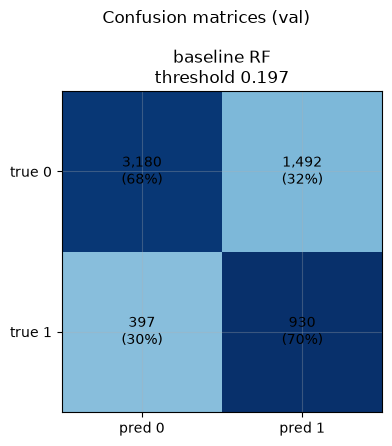

In [12]:
#takes the raw features and trains a baseline RF model to compare against the Markov models
raw_cols = [c for c in train.columns if c != TARGET]
#feature matrix
Xr_tr, Xr_va, Xr_te = train[raw_cols], validation[raw_cols], test[raw_cols]

#baseline evaluation function for the raw features
def evaluate(p, y):
    return {"AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p),
            "LogLoss": log_loss(y, np.clip(p,1e-6,1-1e-6)), "Brier": brier_score_loss(y, p)
            }

#fit the rf
rf0 = RandomForestClassifier(n_estimators=100 if FAST else 300, min_samples_leaf=1, n_jobs=NJ, random_state=SEED, oob_score=True)
rf0.fit(Xr_tr, y_tr)
#score the rf on the validation set and print the results
base = {"val": evaluate(rf0.predict_proba(Xr_va)[:,1], y_va), "OOB accuracy": rf0.oob_score_}
print(pd.DataFrame(base["val"], index=["baseline RF (raw)"]).round(4)); print("OOB accuracy:", round(rf0.oob_score_,4))
print("Majority-class accuracy:", round(1-y_va.mean(),4))

thr = 0.3  
pred = (rf0.predict_proba(Xr_va)[:, 1] >= thr).astype(int)
plot_confusion(
    {"baseline RF": {"p_va": rf0.predict_proba(Xr_va)[:, 1]}},
    split="val"
)





These inital results are promising for a baseline model the accuracy is higher than assigning majority class blankly and the other performance metrics arent worrying. The confusion matrix is able to This is not necesarrily an indicator that there is no bias but that the model is capable of a moderate performance. The flagged customer is approximately 1.7 times more likely to default than a random customer would be. 


### 4.5.2 Numerical Checks

The following code illustrates two key mechanisms behind a Random Forest. First, it compares candidate thresholds for PAY_1, LIMIT_BAL and AGE, identifying which split produces the largest reduction in Gini impurity, a measure of how mixed the classes are. Second, it simulates bootstrap sampling to show the proportion of unique training observations included in each sample, comparing the result with the theoretical value of approximately 63.2%


In [13]:
# (a) Gini and split gain: worked example on the strongest raw predictor
def gini(y): p = np.mean(y); return 2*p*(1-p)
def best_split(x, y):
    xs = np.unique(np.quantile(x, np.linspace(.02,.98,49)))
    gains = []
    for t in xs:
        L = x <= t; nL = L.sum()
        gains.append(gini(y) - nL/len(y)*gini(y[L]) - (1-nL/len(y))*gini(y[~L]))
    i = int(np.argmax(gains)); return xs[i], gains[i]
for c in ["PAY_1", "LIMIT_BAL", "AGE"]:
    t, g = best_split(train[c].values, y_tr); print(f"{c:10s} best threshold {t:>10.1f}  gain {g:.5f}")
print("Parent Gini:", round(gini(y_tr),4))

# (b) bootstrap: fraction of rows in-bag
rng = np.random.default_rng(SEED); n = len(y_tr)
inbag = [len(np.unique(rng.integers(0, n, n)))/n for _ in range(50)]
print("Mean in-bag fraction:", round(np.mean(inbag),4), " theory 1-1/e =", round(1-np.exp(-1),4))

PAY_1      best threshold        1.0  gain 0.05207
LIMIT_BAL  best threshold   120000.0  gain 0.00826
AGE        best threshold       24.0  gain 0.00080
Parent Gini: 0.3445
Mean in-bag fraction: 0.6326  theory 1-1/e = 0.6321


- `PAY_1` achieved the highest gain, so it will be chosen as the splitting feature for this node.
- Seeing the empirical mean in-bag fraction (0.6326) match the theoretical limit ($1 - 1/e \approx 0.6321$) confirms that the bootstrap sampling mechanism for the forest's training iterations is working correctly.
- 0.3445 is consistent with approximately 22.1% defaulters and 77.9% non-defaulters: $G≈2(0.2213)(0.7787)≈0.3445.$

## 4.6 Feature engineering

### 4.6.1 Feature Choices


Using the dataset there is thousands of features which could be created to train our model, so it is improtatnt to pick ones which we have reason to believe will make the most difference. The following features summarise repayment behaviour, credit utilisation and changes over time. They retain information from the original columns while making potentially useful patterns directly available to the models.


| Feature | What it measures | Reason for creating it |
|---|---|---|
| `n_late` | Number of months with a positive repayment-status code. | Measures how frequently the customer has experienced repayment delays, distinguishing persistent lateness from an isolated incident. |
| `max_delay` | Maximum repayment-status code across the six months. | Captures the most severe recorded delay, which may be obscured by an average of otherwise timely payments. |
| `mean_pay` | Mean repayment-status code across the six months. | Summarises the overall repayment-status history. However, it is an average of status codes, not payment amounts or an exact average delay, because non-positive codes describe different repayment states. |
| `recent_late` | Number of the two most recent months with a positive repayment-status code. | Highlights recent repayment difficulties that may be more relevant to next-month default than older delays. |
| `n_revolve` | Number of months with repayment-status code zero. | Intended to measure how frequently the customer uses revolving credit, potentially distinguishing customers who carry balances from those who repay in full. This interpretation requires checking that code zero means revolving credit in the cleaned dataset. |
| `pay_slope` | Latest repayment-status code minus the oldest code. | Captures the direction of change in repayment status: positive values indicate a higher status code recently, while negative values indicate a lower code. It is an endpoint difference, not a fitted trend or a precise change in months overdue when non-positive codes are involved. |
| `util_1` | Latest bill amount divided by the credit limit. | Expresses the latest balance relative to available credit, allowing comparison between customers with different credit limits. High values indicate limited remaining credit capacity, which could be significant. |
| `util_mean` | Mean bill amount divided by the credit limit. | Summarises typical balance-to-limit utilisation across the six months, reducing dependence on a single month's bill. |
| `util_max` | Maximum bill amount divided by the credit limit. | Captures peak utilisation that an average could hide, potentially identifying episodes of high credit usage. |
| `bill_trend` | Latest bill minus oldest bill, divided by the credit limit. | Measures the net change in balances relative to the customer's credit limit. Rising balances may reflect increasing borrowing or spending; this feature does not by itself establish financial distress. |
| `repay_ratio` | Total recorded payments divided by the sum of non-negative bill amounts, plus 1. | Summarises payment amounts relative to recorded balances. It may distinguish relatively low from relatively high repayment activity, but it is not an exact fraction of debt repaid because successive monthly bills can contain overlapping debt. |
| `zero_pay_n` | Number of months with a recorded payment amount of zero. | Identifies repeated months without payments. These may indicate repayment difficulties, but can also occur when no payment is required, so the feature should be interpreted alongside bills and repayment statuses. |
| `bill_vol` | Standard deviation of monthly bills divided by their mean absolute amount, plus 1. | Measures balance variability relative to typical balance size, distinguishing stable balances from fluctuating ones without relying solely on their monetary scale. |

### Implementation and interpretation notes

- `bill_cols` must be ordered from oldest to newest, so `B[:, 0]` is the oldest bill and `B[:, -1]` is the latest.
- `PAY_1` is treated as the latest repayment status and `PAY_6` as the oldest.
- `mean_pay` refers to repayment-status codes, not monetary payments; a clearer name would be `mean_pay_status`.
- The `+1` terms prevent division by zero but can still produce large ratios when bill amounts are small.
- The utilisation features assume `LIMIT_BAL` is strictly positive; zero credit limits require separate handling.
- These features are candidate predictors, not established causes of default. Their usefulness should be assessed through validation and feature-group ablation.

In [14]:
def make_features(d):
    X = d.drop(columns=TARGET).copy(); L = X["LIMIT_BAL"]
    B, A = X[bill_cols].values, X[amt_cols].values
    X["n_late"]      = (X[pay_cols] > 0).sum(axis=1)
    X["max_delay"]   = X[pay_cols].max(axis=1)
    X["mean_pay"]    = X[pay_cols].mean(axis=1)
    X["recent_late"] = (X[["PAY_1", "PAY_2"]] > 0).sum(axis=1)
    X["n_revolve"]   = (X[pay_cols] == 0).sum(axis=1)
    X["pay_slope"]   = X["PAY_1"] - X["PAY_6"]
    X["util_1"]      = B[:, -1] / L
    X["util_mean"]   = B.mean(axis=1) / L
    X["util_max"]    = B.max(axis=1) / L
    X["bill_trend"]  = (B[:, -1] - B[:, 0]) / L
    X["repay_ratio"] = A.sum(axis=1) / (np.clip(B, 0, None).sum(axis=1) + 1)
    X["zero_pay_n"]  = (A == 0).sum(axis=1)
    X["bill_vol"]    = B.std(axis=1) / (np.abs(B).mean(axis=1) + 1)
    return X
X_tr, X_va, X_te = make_features(train), make_features(validation), make_features(test)



### 4.6.2 New Models

Next we need to train new models using this data in conjunction with the origonal dataset so we can see if the new features add significant predictive power to the model. Along wiht another random forest, we will create a HGB classiffier, which uses a different method of building trees than the random forest

#### How histogram-based gradient boosting works

Histogram-based gradient boosting (HGB) is an ensemble method that builds decision trees sequentially, instead of independently then averaging. Each new tree updates the predictions of the existing ensemble to reduce its loss. 

**Predicting default probabilities**

For binary classification, the model first predicts a score, $F(x)$, on the log-odds scale. It converts this score into a default probability using the logistic function:

$$
p(x) = \frac{1}{1+\exp(-F(x))}.
$$

A larger score corresponds to a higher predicted probability of default. The initial score is based on the default proportion in the training data, before any trees are added.

**Minimise loss**

The model is trained to minimise binary log loss:

$$
L = -\sum_{i=1}^{n} \left[ y_i\log(p_i)+(1-y_i)\log(1-p_i) \right],
$$

where $y_i$ is the observed default indicator and $p_i$ is the predicted default probability.

Log loss penalises incorrect predictions, particularly confident errors. For example, predicting a very low probability for a customer who subsequently defaults incurs a large loss.

**Adding corrective trees**

At each boosting iteration, the model calculates how its current predictions should change to reduce the loss. For binary log loss, the gradient with respect to the current score is:

$$
g_i = p_i-y_i.
$$

For an actual defaulter whose predicted probability is too low, this gradient is negative, encouraging an upward adjustment to the score. For a non-defaulter with an unnecessarily high predicted probability, it encourages a downward adjustment.

HGB uses both these gradients and second derivatives of the loss to construct the next tree. The ensemble is updated as:

$$
F_m(x)=F_{m-1}(x)+\eta T_m(x),
$$

where $T_m(x)$ is the new tree's output and $\eta$ is the learning rate. In our model, `learning_rate=0.05`, so each tree contributes a relatively small update.

**Histogram-based splitting**

Before building the trees, numerical feature values are grouped into bins. When searching for a split, the algorithm considers bin boundaries rather than every distinct feature value.

For example, `util_mean` values are grouped, and the model searches for the most useful divisions between these intervals. This reduces the number of candidate splits and makes training more efficient.

**Controlling model complexity**

Our implementation uses:

- `max_depth=4`: this limits the complexity of individual decision rules while allowing interactions between features.
- `max_iter=200`: allows a maximum of 200 boosting iterations. 
- `learning_rate=0.05`: limits each tree's contribution, making the updates more gradual.
- `l2_regularization=1`: penalises large leaf values, discouraging overly strong prediction updates, to reduce .
- `random_state=42`: makes the random elements of training reproducible.

These restrictions aim to reduce overfitting, but their effectiveness must be assessed using validation performance.


In [15]:

models = {
    "RF": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "HGB": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=200,
                                          l2_regularization=1, random_state=42),
}
for m in models.values(): m.fit(X_tr, y_tr)

### 4.6.3 Tuning and Calibration

Now that we have the models we need to optimise our hyperparameters to find what settings improve predictive performance. These are choices made before training, such as tree depth, minimum leaf size and learning rate In order to do this we will use RandomizedSearchCV to sample combinations from specified search spaces and evaluate each combination using three-fold stratified cross-validation. This allows us to compare candidate settings without relying on a single training–validation split.

**How does it work?**

 - The data is divided by class, then split in this case into three equal folds with each having the same class mix.
 - A random combination of hyperparameters is chosen from the given space (only does 10 combinations for RF and 15 for HGB) rather than an exhaustive list of all combinations
 - For each combination a model fit on two of the folds and score on the held out fold.
 - Each observation is used once for validation and twice for fitting, then the final estimate is the mean of the three results
 - The three held-out ROC AUC scores are averaged to produce that combination’s cross-validation score. The search then selects the combination with the highest mean score.

To keep the RF search efficient, we use 150 trees while tuning, then train the selected settings with 500 trees. For HGB, early stopping allows training to finish before the maximum of 500 boosting iterations. Finally, a fixed random seed makes the fold assignments and sampled parameter combinations reproducible.


In [16]:
import time, joblib
from scipy.stats import randint, loguniform
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

SEED = 42
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # 3 folds 

# --- RF: search with fewer, cheaper trees, then refit the winner with more trees ---
rf_space = {"min_samples_leaf": randint(5, 80),
            "max_features": ["sqrt", 0.2, 0.35],
            "max_depth": [None, 12, 18],
            "max_samples": [0.5, 0.7]}            # smaller bootstrap = faster trees
t0 = time.time()
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=150, n_jobs=1, random_state=SEED),
    rf_space, n_iter=10, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=SEED, verbose=1,
).fit(X_tr, y_tr)
print(f"RF search: {time.time()-t0:.0f}s  CV AUC {rf_search.best_score_:.4f}  {rf_search.best_params_}")

# --- HGB: usually fast; early stopping removes the need to tune max_iter ---
hgb_space = {"learning_rate": loguniform(0.02, 0.2),
             "max_depth": [3, 4, 5, None],
             "max_leaf_nodes": randint(8, 40),
             "min_samples_leaf": randint(20, 200),
             "l2_regularization": loguniform(1e-2, 1e2)}

t0 = time.time()
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(max_iter=500, early_stopping=True, n_iter_no_change=15, random_state=SEED),
    hgb_space, n_iter=15, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=SEED, verbose=1,
).fit(X_tr, y_tr)
print(f"HGB search: {time.time()-t0:.0f}s  CV AUC {hgb_search.best_score_:.4f}  {hgb_search.best_params_}")

# final RF with more trees and all cores
rf_best  = RandomForestClassifier(**{**rf_search.best_params_, "n_estimators": 500, "n_jobs": -1, "random_state": SEED}).fit(X_tr, y_tr)
hgb_best = hgb_search.best_estimator_
joblib.dump({"rf": rf_best, "hgb": hgb_best}, "tuned_models.joblib")   # so you never have to rerun this

Fitting 3 folds for each of 10 candidates, totalling 30 fits
RF search: 25s  CV AUC 0.7805  {'max_depth': 12, 'max_features': 0.35, 'max_samples': 0.7, 'min_samples_leaf': 59}
Fitting 3 folds for each of 15 candidates, totalling 45 fits
HGB search: 3s  CV AUC 0.7816  {'l2_regularization': np.float64(1.7912362571043667), 'learning_rate': np.float64(0.04857876818821363), 'max_depth': 4, 'max_leaf_nodes': 28, 'min_samples_leaf': 149}


['tuned_models.joblib']

## 5.7 Comparison

With the baseline model established and both tree-based ensembles—Random Forest (RF) and Histogram-Based Gradient Boosting (HGB)—tuned and calibrated, we now evaluate their comparative performance on the validation set (`val`). Credit default prediction requires both accurate risk ranking and reliable probability estimates, so we will look at multiple metrics to have a better idea of performace.

1. Firstly we shall compare overall ranking performance using the Area Under the ROC Curve (**AUC**), alongside **Precision-Recall (PR) curves** on the validation split. The ROC curve shows the trade-off between true and false positive rates across all thresholds, while the PR curve highlights the effectiveness of each model at identifying true defaults without being overrun by false alarms in an imbalanced dataset.
2. To assess whether the predicted probabilities reflect true default risk, we examine **log loss** and the **Brier score**, supported by **calibration curves** and **predicted score distributions**. Lower log loss and Brier scores indicate better-calibrated probabilities, while the score distributions reveal how sharply each model separates low- and high-risk customers.
3. **Portfolio Prioritisation (Cumulative Gains):** We plot the **cumulative gains curve** to evaluate what proportion of total defaults can be captured if interventions are targeted at the highest-risk fraction of customers.
4. **Threshold Classification Performance:** Finally, we examine the validation **confusion matrices** at our chosen cost weighting to compare the trade-off between missed defaults (false negatives) and false alarms (false positives), which is an important consideration in practical application.

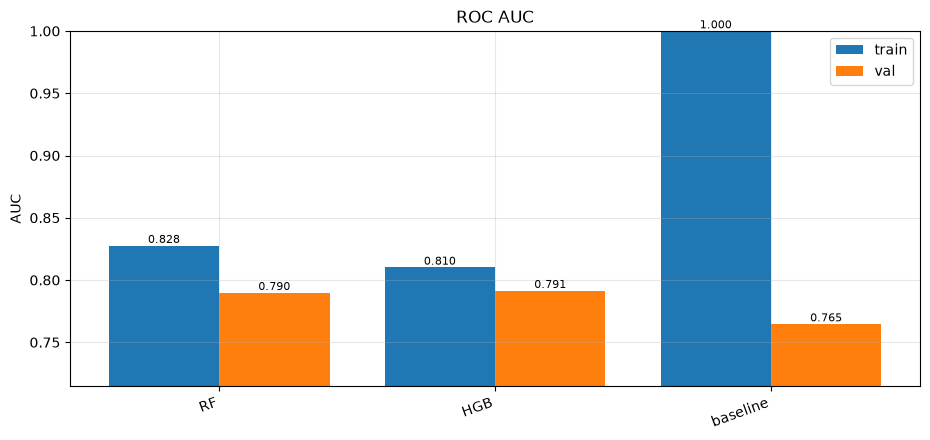

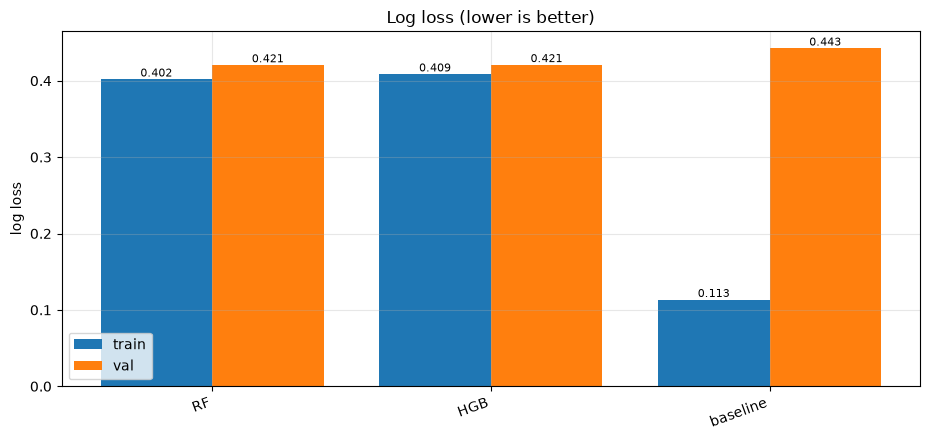

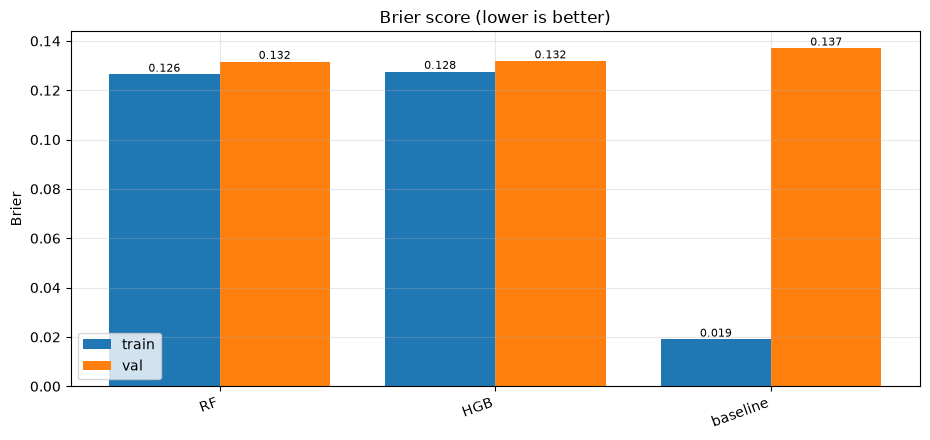

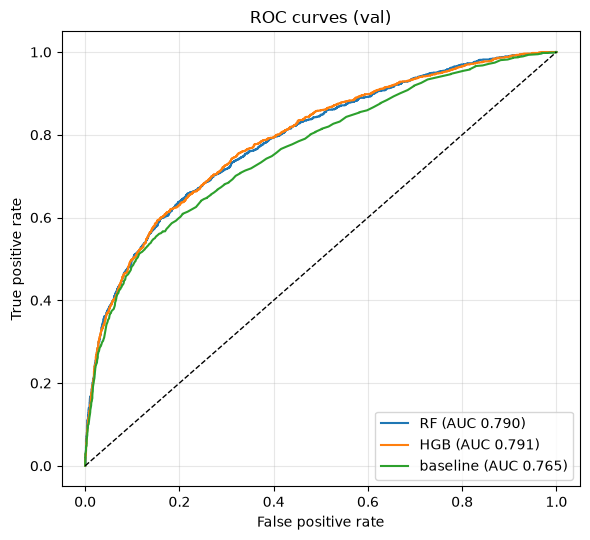

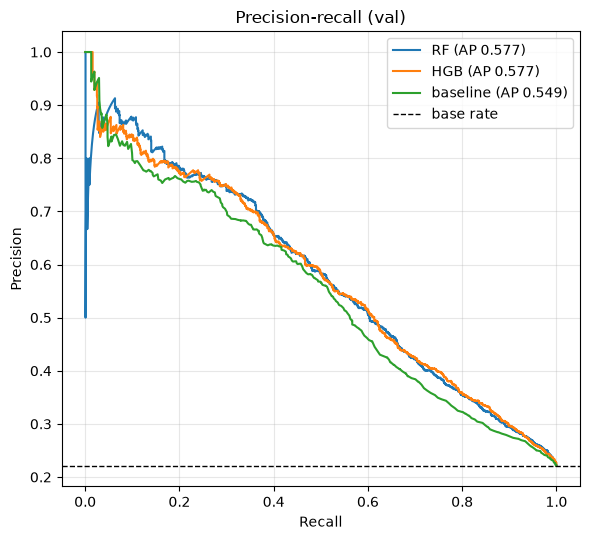

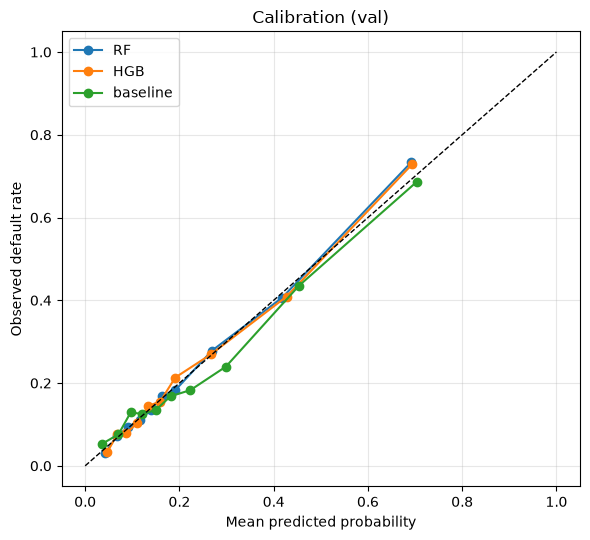

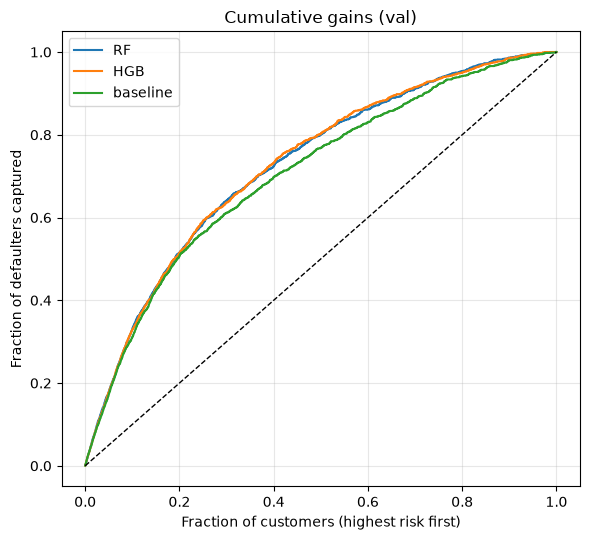

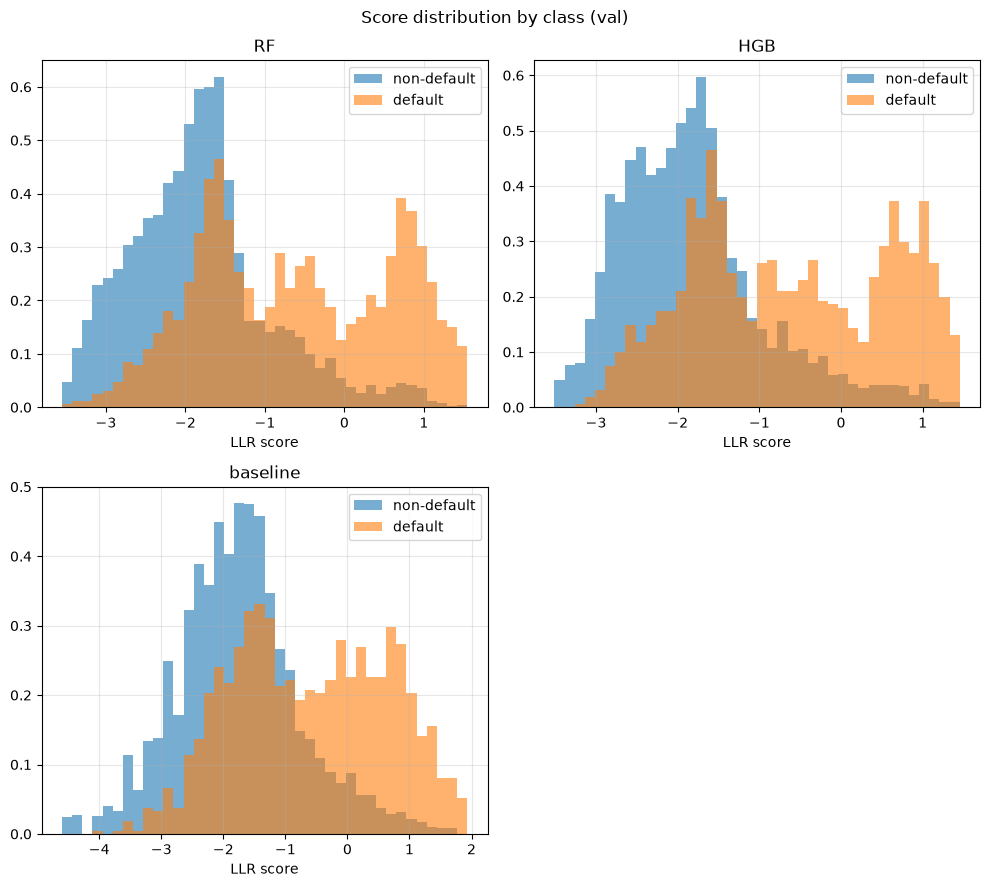

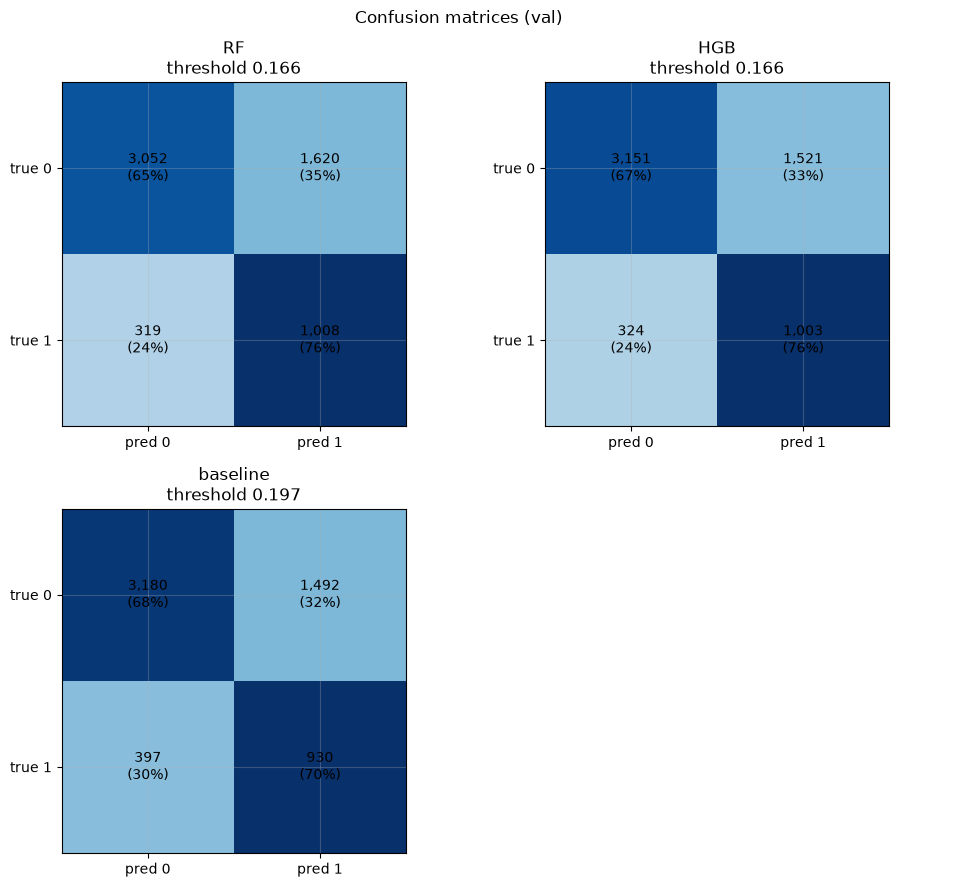

In [17]:
models = {"RF": rf_best, "HGB": hgb_best, "baseline": rf0}

def as_result(model, eps=1e-6):
    out = {}
    for tag, X_full in [("tr", X_tr), ("va", X_va)]:
        X = X_full[model.feature_names_in_]          # use exactly the columns this model was trained on
        p = model.predict_proba(X)[:, 1]
        out[f"p_{tag}"] = p
        pc = np.clip(p, eps, 1 - eps)
        out[f"sc_{tag}"] = np.log(pc / (1 - pc))      # log-odds, used by plot_score_distribution
    return out

results = {name: as_result(m) for name, m in models.items()}

auc_vals   = plot_auc(results)
ll_vals    = plot_logloss(results)
brier_vals = plot_brier(results)

plot_roc(results, split="val")
plot_pr(results, split="val")
plot_calibration(results, split="val")
plot_gains(results, split="val")
plot_score_distribution(results, split="val")
plot_confusion(results, split="val")
 

**Interpretation**

1. There is a clear gain in performance of the updated models over the baseline with approximately a 0.025 gain in AUC and 0.028 in AP, and worse log loss and brier scores. The baseline model shows extreme difference in `train` and `val` scores which shows it is overfit due to unpruned trees but the averaging of the random forest limits how poor the model could perform

2. The RF and HGB models both have almost identical performance over all metrics. The AUC differs by 0.001 which definitely falls under moise of the model, and the AP, log loss and Brier values are identical to three decimals. The drop of the RF PR curve is sharp and short so not a significant sign of the model being worse. 

3. The score distributions for each show clear seperations of large proportions of each class with one caveat. Near the centre of all models there are a few strips with both large amounts of defaulters and non defaulters, with the data we have it seems the behavour of certain types of deafulters is obscured. With more data or maybe a specifically engeneered feature a distinguishing behavour could emerge and help improve the classifiers further.


## 5.8 Conclusion

We choose the HGB model as the best final model over the tuned Random Forest. Both models achieve effectively identical validation performance across the metrics considered, so neither demonstrates a clear advantage in predictive performance on the validation set. The HGB model has a train–validation AUC gap of 0.019, compared with 0.038 for the Random Forest. This smaller gap indicates that its validation performance remains closer to its training performance, so less overfitting in this experiment. Its faster training provides an additional practical advantage, making it our preferred choice when predictive performance is otherwise comparable. We will carry both models forward to the final test section. The held out test data could distinguish the tie on metric performance of the models on validation data.
